In [1]:
if(!require("pacman")) install.packages("pacman")
pacman::p_load(knitr, arrow, gt, ggsci, binom, tidyverse)

Loading required package: pacman



# Data

Everything I need is already in the analysis sample - the three algorithm columns, `combined_group`, and the complaint cluster.

In [2]:
# the comparison tables are wide, so give print() some room
options(width = 250)

# Ill only keep some columns for this analysis
ed_data <- read_parquet(
  "../ANALYSIS/ed_single.parquet",
  col_select = c(
    nyu,
    res,
    acuity_out,
    combined_group,
    cluster,
    age,
    gender,
    race,
    acuity,
    pain,
    length_of_stay,
    disposition,
   
    icd_chapter
  )
)

print(dim(ed_data))

[1] 201106     13


Add the grouping columns. SINGLE is one algorithm, MULTIPLE is two or three, and the unflagged visits stay in as a reference.

In [3]:
cluster_labels <- c(
  "Lower back pain",
  "Influenza like illness",
  "Vehicle collision + Altered mental status",
  "Chest pain + dyspnea",
  "Shortness breath",
  "Abdomen pain",
  "Leg + knee pain",
  "Wound evaluation",
  "Alcohol intoxication",
  "Nausea vomiting",
  "Suicidal ideation",
  "Fall transfer"
)

ed_data <- ed_data |>
  mutate(
    n_algorithms = nyu + res + acuity_out,
    group = case_when(
      n_algorithms == 0 ~ "UNFLAGGED",
      n_algorithms == 1 ~ "SINGLE",
      n_algorithms >= 2 ~ "MULTIPLE"
    ),
    group = factor(group, levels = c("SINGLE", "MULTIPLE", "UNFLAGGED")),
    # collapse race the same way as the descriptive table
    race = case_when(
      str_detect(race, "WHITE") ~ "White",
      str_detect(race, "BLACK") ~ "Black",
      str_detect(race, "HISPANIC") ~ "Hispanic/Latino",
      str_detect(race, "ASIAN") ~ "Asian",
      T ~ "Other"
    ),
    female = as.integer(gender == "F"),
    home = as.integer(disposition == "HOME"),
    admitted = as.integer(disposition == "ADMITTED"),
    left_early = as.integer(disposition %in% c(
      "LEFT WITHOUT BEING SEEN",
      "ELOPED",
      "LEFT AGAINST MEDICAL ADVICE"
    )),
    cluster_label = factor(cluster_labels[cluster + 1], levels = cluster_labels)
  )

ed_data |>
  count(group) |>
  kable()



|group     |      n|
|:---------|------:|
|SINGLE    |  72236|
|MULTIPLE  |  28332|
|UNFLAGGED | 100538|

# Check the numbers

Before anything else, check the file still gives the counts the rest of the pipeline reports.

In [4]:
grp_n <- ed_data |>
  count(combined_group) |>
  deframe()

alg_sum <- sum(ed_data$nyu) + sum(ed_data$res) + sum(ed_data$acuity_out)

checks <- tribble(
  ~check,                          ~expected, ~observed,
  "Rows in the analysis sample",   201106,    nrow(ed_data),
  "Flagged by >= 1 algorithm",     100568,    sum(ed_data$n_algorithms >= 1),
  "SINGLE (1 algorithm)",          72236,     sum(ed_data$n_algorithms == 1),
  "MULTIPLE (2 or 3 algorithms)",  28332,     sum(ed_data$n_algorithms >= 2),
  "000 Unflagged",                 100538,    unname(grp_n["000"]),
  "100 Diagnosis",                 44119,     unname(grp_n["100"]),
  "010 Resources",                 23427,     unname(grp_n["010"]),
  "001 Triage-Acuity",             4690,      unname(grp_n["001"]),
  "110 Diagnosis+Resources",       17306,     unname(grp_n["110"]),
  "101 Diagnosis+Triage-Acuity",   3578,      unname(grp_n["101"]),
  "011 Resources+Triage-Acuity",   4278,      unname(grp_n["011"]),
  "111 All three",                 3170,      unname(grp_n["111"]),
  "Diagnosis total",               68173,     sum(ed_data$nyu),
  "Resources total",               48181,     sum(ed_data$res),
  "Triage-Acuity total",           15716,     sum(ed_data$acuity_out),
  "Three totals added together",   132070,    alg_sum,
  "Excess over the union",         31502,     alg_sum - sum(ed_data$n_algorithms >= 1)
) |>
  mutate(
    result = if_else(expected == observed, "PASS", "FAIL")
  )

checks |>
  kable()

if (any(checks$result == "FAIL")) {
  stop("Verification failed - stop and look at the data before going further.")
}



|check                        | expected| observed|result |
|:----------------------------|--------:|--------:|:------|
|Rows in the analysis sample  |   201106|   201106|PASS   |
|Flagged by >= 1 algorithm    |   100568|   100568|PASS   |
|SINGLE (1 algorithm)         |    72236|    72236|PASS   |
|MULTIPLE (2 or 3 algorithms) |    28332|    28332|PASS   |
|000 Unflagged                |   100538|   100538|PASS   |
|100 Diagnosis                |    44119|    44119|PASS   |
|010 Resources                |    23427|    23427|PASS   |
|001 Triage-Acuity            |     4690|     4690|PASS   |
|110 Diagnosis+Resources      |    17306|    17306|PASS   |
|101 Diagnosis+Triage-Acuity  |     3578|     3578|PASS   |
|011 Resources+Triage-Acuity  |     4278|     4278|PASS   |
|111 All three                |     3170|     3170|PASS   |
|Diagnosis total              |    68173|    68173|PASS   |
|Resources total              |    48181|    48181|PASS   |
|Triage-Acuity total          |    157

All pass, so I can carry on.

# Where the 100,568 comes from

It is a union, not a sum. Every visit sits in exactly one cell of `combined_group`, so the seven cells where something fires just add up.

In [5]:
overlap <- ed_data |>
  filter(n_algorithms >= 1) |>
  count(combined_group, n_algorithms) |>
  mutate(
    algorithms = case_when(
      combined_group == "100" ~ "Diagnosis",
      combined_group == "010" ~ "Resources",
      combined_group == "001" ~ "Triage-Acuity",
      combined_group == "110" ~ "Diagnosis + Resources",
      combined_group == "101" ~ "Diagnosis + Triage-Acuity",
      combined_group == "011" ~ "Resources + Triage-Acuity",
      combined_group == "111" ~ "All three"
    ),
    pct_of_flagged = round(100 * n / sum(n), 1),
    pct_of_sample = round(100 * n / nrow(ed_data), 1)
  ) |>
  arrange(n_algorithms, desc(n)) |>
  select(combined_group, algorithms, n_algorithms, n, pct_of_flagged, pct_of_sample)

overlap |>
  kable()

print(paste("Seven cells add to:", sum(overlap$n)))
print(paste("SINGLE:", sum(overlap$n[overlap$n_algorithms == 1])))
print(paste("MULTIPLE:", sum(overlap$n[overlap$n_algorithms >= 2])))



|combined_group |algorithms                | n_algorithms|     n| pct_of_flagged| pct_of_sample|
|:--------------|:-------------------------|------------:|-----:|--------------:|-------------:|
|100            |Diagnosis                 |            1| 44119|           43.9|          21.9|
|010            |Resources                 |            1| 23427|           23.3|          11.6|
|001            |Triage-Acuity             |            1|  4690|            4.7|           2.3|
|110            |Diagnosis + Resources     |            2| 17306|           17.2|           8.6|
|011            |Resources + Triage-Acuity |            2|  4278|            4.3|           2.1|
|101            |Diagnosis + Triage-Acuity |            2|  3578|            3.6|           1.8|
|111            |All three                 |            3|  3170|            3.2|           1.6|

[1] "Seven cells add to: 100568"


[1] "SINGLE: 72236"


[1] "MULTIPLE: 28332"


Adding the three algorithm totals instead gives a much bigger number.

In [6]:
alg_totals <- tibble(
  algorithm = c("Diagnosis", "Resources", "Triage-Acuity"),
  n = c(sum(ed_data$nyu), sum(ed_data$res), sum(ed_data$acuity_out))
) |>
  mutate(
    pct_of_sample = round(100 * n / nrow(ed_data), 1)
  )

alg_totals |>
  kable()

print(paste("Sum of the three totals:", sum(alg_totals$n)))
print(paste("Union (>= 1 algorithm):", sum(ed_data$n_algorithms >= 1)))
print(paste("Excess:", sum(alg_totals$n) - sum(ed_data$n_algorithms >= 1)))



|algorithm     |     n| pct_of_sample|
|:-------------|-----:|-------------:|
|Diagnosis     | 68173|          33.9|
|Resources     | 48181|          24.0|
|Triage-Acuity | 15716|           7.8|

[1] "Sum of the three totals: 132070"


[1] "Union (>= 1 algorithm): 100568"


[1] "Excess: 31502"


The 31,502 excess is exactly the double counting. A two-algorithm visit is counted one time too many, a three-algorithm visit two times too many.

In [7]:
excess <- ed_data |>
  filter(n_algorithms >= 2) |>
  count(n_algorithms) |>
  mutate(
    extra_counts_each = n_algorithms - 1,
    excess_counts = n * extra_counts_each
  )

excess |>
  kable()

print(paste("Visits counted more than once:", sum(excess$n)))
print(paste("Excess counts:", sum(excess$excess_counts)))



| n_algorithms|     n| extra_counts_each| excess_counts|
|------------:|-----:|-----------------:|-------------:|
|            2| 25162|                 1|         25162|
|            3|  3170|                 2|          6340|

[1] "Visits counted more than once: 28332"


[1] "Excess counts: 31502"


So 132,070 - 31,502 = 100,568, and 28,332 of those visits carry more than one flag. That is the group I want to look at.

# The definitional problem

Before comparing anything I have to be careful about which variables the algorithms already control. MULTIPLE carries the constraining flags far more often than SINGLE, so anything those flags fix will differ between the groups whether or not something clinically different is going on.

In [8]:
flag_prevalence <- ed_data |>
  group_by(group) |>
  summarise(
    n = n(),
    Diagnosis = round(100 * mean(nyu), 1),
    Resources = round(100 * mean(res), 1),
    `Triage-Acuity` = round(100 * mean(acuity_out), 1),
    .groups = "drop"
  )

flag_prevalence |>
  kable()



|group     |      n| Diagnosis| Resources| Triage-Acuity|
|:---------|------:|---------:|---------:|-------------:|
|SINGLE    |  72236|      61.1|      32.4|           6.5|
|MULTIPLE  |  28332|      84.9|      87.4|          38.9|
|UNFLAGGED | 100538|       0.0|       0.0|           0.0|

`acuity_out` is not a correlate of triage acuity, it is a recode of it. And `res` forbids ADMITTED, TRANSFER and EXPIRED. Check both.

In [9]:
print(paste(
  "Rows where acuity_out != (acuity >= 4):",
  sum(ed_data$acuity_out != as.integer(ed_data$acuity >= 4))
))

ed_data |>
  filter(res == 1) |>
  count(disposition, sort = T) |>
  kable()

[1] "Rows where acuity_out != (acuity >= 4): 0"




|disposition                 |     n|
|:---------------------------|-----:|
|HOME                        | 43242|
|LEFT WITHOUT BEING SEEN     |  2546|
|ELOPED                      |  1246|
|OTHER                       |   818|
|LEFT AGAINST MEDICAL ADVICE |   329|

Zero violations both times. So the acuity and admission differences between SINGLE and MULTIPLE are largely arithmetic, not empirical.

Functions for the tables below.

In [10]:
# Functions for the tables
prop_fn <- function(x, n) {
  ci <- binom::binom.confint(sum(x), n, method = "agresti-coull")
  proportion = ci$mean*100
  lower_95 = ci$lower*100
  upper_95 = ci$upper*100
  sprintf("%.1f [%.1f-%.1f]", proportion, lower_95, upper_95)
}

summarise_mean <- function(x) {
  t_result <- t.test(x, conf.level = 0.95)
  sprintf("%.2f [%.2f-%.2f]", t_result$estimate, t_result$conf.int[1], t_result$conf.int[2])
}

summarise_median <- function(x) {
  q1 <- quantile(x, 0.25, names = FALSE, na.rm = TRUE)
  med <- median(x, na.rm = TRUE)
  q3 <- quantile(x, 0.75, names = FALSE, na.rm = TRUE)
  sprintf("%.1f [%.1f-%.1f]", med, q1, q3)
}

# SMDs, continuous and for a single category's proportion
smd_cont <- function(x1, x2) {
  (mean(x1, na.rm = TRUE) - mean(x2, na.rm = TRUE)) /
    sqrt((sd(x1, na.rm = TRUE)^2 + sd(x2, na.rm = TRUE)^2) / 2)
}

smd_prop <- function(p1, p2) {
  (p1 - p2) / sqrt((p1 * (1 - p1) + p2 * (1 - p2)) / 2)
}

Split the three groups out once so I am not filtering over and over.

In [11]:
single <- ed_data |> filter(group == "SINGLE")
multiple <- ed_data |> filter(group == "MULTIPLE")
unflagged <- ed_data |> filter(group == "UNFLAGGED")

print(c(SINGLE = nrow(single), MULTIPLE = nrow(multiple), UNFLAGGED = nrow(unflagged)))

   SINGLE  MULTIPLE UNFLAGGED 
    72236     28332    100538 


Now show how much of the acuity gap is the recode. Raw means, then the same means restricted to visits that do not carry the Triage-Acuity flag.

In [12]:
acuity_check <- bind_rows(
  ed_data |> mutate(stratum = "Raw"),
  ed_data |> filter(acuity_out == 0) |> mutate(stratum = "Without the Triage-Acuity flag")
) |>
  group_by(stratum, group) |>
  summarise(
    n = n(),
    mean_acuity = round(mean(acuity), 2),
    .groups = "drop"
  ) |>
  pivot_wider(
    names_from = group,
    values_from = c(n, mean_acuity)
  )

acuity_check |>
  kable()

print(paste(
  "SMD raw:",
  round(smd_cont(single$acuity, multiple$acuity), 3),
  "| SMD without the Triage-Acuity flag:",
  round(smd_cont(single$acuity[single$acuity_out == 0], multiple$acuity[multiple$acuity_out == 0]), 3)
))



|stratum                        | n_SINGLE| n_MULTIPLE| n_UNFLAGGED| mean_acuity_SINGLE| mean_acuity_MULTIPLE| mean_acuity_UNFLAGGED|
|:------------------------------|--------:|----------:|-----------:|------------------:|--------------------:|---------------------:|
|Raw                            |    72236|      28332|      100538|               2.76|                 3.28|                  2.34|
|Without the Triage-Acuity flag |    67546|      17306|      100538|               2.67|                 2.80|                  2.34|

[1] "SMD raw: -0.792 | SMD without the Triage-Acuity flag: -0.264"


2.76 vs 3.28 becomes 2.67 vs 2.80. Three quarters of the gap was the definition. Something small is left, but it is not what the raw numbers looked like.

Admission is worse, because there is no stratum in which to look at it. A visit carrying neither the Resources nor the Triage-Acuity flag can only have been flagged on diagnosis, which makes it single by necessity.

In [13]:
ed_data |>
  filter(res == 0, acuity_out == 0) |>
  count(group, combined_group) |>
  kable()



|group     |combined_group |      n|
|:---------|:--------------|------:|
|SINGLE    |100            |  44119|
|UNFLAGGED |000            | 100538|

Only 100 and 000 survive - there are no multi-algorithm visits at all in that stratum. So acuity and admission cannot be read as findings here, however big the difference looks. I will still report them, marked as definitional, because leaving them out would be worse.

# SINGLE vs MULTIPLE

The groups run from 28,332 to 100,538. At that size everything is significant and the p-value tells the reader nothing, so I use standardised mean differences with the usual |SMD| > 0.1 threshold.

In [14]:
comparison_rows <- list()

add_stat <- function(variable, statistic, s_val, m_val, u_val,
                     smd = NA_real_, status = "clean") {
  comparison_rows[[length(comparison_rows) + 1]] <<- tibble(
    Variable = variable,
    Statistic = statistic,
    SINGLE = s_val,
    MULTIPLE = m_val,
    UNFLAGGED = u_val,
    SMD = if_else(is.na(smd), "", sprintf("%+.3f", smd)),
    `|SMD|>0.1` = if_else(is.na(smd), "", if_else(abs(smd) > 0.1, "yes", "no")),
    Status = status
  )
}

A positive SMD means the value is higher in SINGLE.

In [15]:
# Age
add_stat(
  "Age (years)", "Mean [95% CI]",
  summarise_mean(single$age), summarise_mean(multiple$age), summarise_mean(unflagged$age),
  smd_cont(single$age, multiple$age)
)
add_stat(
  "Age (years)", "Median [IQR]",
  summarise_median(single$age), summarise_median(multiple$age), summarise_median(unflagged$age)
)

# Gender
add_stat(
  "Gender", "Female, % [95% CI]",
  prop_fn(single$female, nrow(single)),
  prop_fn(multiple$female, nrow(multiple)),
  prop_fn(unflagged$female, nrow(unflagged)),
  smd_prop(mean(single$female), mean(multiple$female))
)

# Self-reported race
for (r in c("White", "Black", "Hispanic/Latino", "Asian", "Other")) {
  add_stat(
    "Self-reported race", paste0(r, ", % [95% CI]"),
    prop_fn(as.integer(single$race == r), nrow(single)),
    prop_fn(as.integer(multiple$race == r), nrow(multiple)),
    prop_fn(as.integer(unflagged$race == r), nrow(unflagged)),
    smd_prop(mean(single$race == r), mean(multiple$race == r))
  )
}

# Triage acuity - the algorithm input
add_stat(
  "Triage acuity (1 = most acute)", "Mean [95% CI]",
  summarise_mean(single$acuity), summarise_mean(multiple$acuity), summarise_mean(unflagged$acuity),
  smd_cont(single$acuity, multiple$acuity),
  "definitional"
)
add_stat(
  "Triage acuity (1 = most acute)", "Median [IQR]",
  summarise_median(single$acuity), summarise_median(multiple$acuity), summarise_median(unflagged$acuity),
  NA_real_, "definitional"
)
add_stat(
  "Triage acuity (1 = most acute)", "Mean, without the Triage-Acuity flag",
  summarise_mean(single$acuity[single$acuity_out == 0]),
  summarise_mean(multiple$acuity[multiple$acuity_out == 0]),
  summarise_mean(unflagged$acuity),
  smd_cont(single$acuity[single$acuity_out == 0], multiple$acuity[multiple$acuity_out == 0]),
  "constraint removed"
)

# Pain
add_stat(
  "Pain score (0-10)", "Mean [95% CI]",
  summarise_mean(single$pain), summarise_mean(multiple$pain), summarise_mean(unflagged$pain),
  smd_cont(single$pain, multiple$pain)
)
add_stat(
  "Pain score (0-10)", "Median [IQR]",
  summarise_median(single$pain), summarise_median(multiple$pain), summarise_median(unflagged$pain)
)

# Length of stay
add_stat(
  "Length of stay (mins)", "Mean [95% CI]",
  summarise_mean(single$length_of_stay), summarise_mean(multiple$length_of_stay),
  summarise_mean(unflagged$length_of_stay),
  smd_cont(single$length_of_stay, multiple$length_of_stay)
)
add_stat(
  "Length of stay (mins)", "Median [IQR]",
  summarise_median(single$length_of_stay), summarise_median(multiple$length_of_stay),
  summarise_median(unflagged$length_of_stay)
)
add_stat(
  "Length of stay (mins)", "Mean, non-admitted visits only",
  summarise_mean(single$length_of_stay[single$admitted == 0]),
  summarise_mean(multiple$length_of_stay[multiple$admitted == 0]),
  summarise_mean(unflagged$length_of_stay[unflagged$admitted == 0]),
  smd_cont(single$length_of_stay[single$admitted == 0], multiple$length_of_stay[multiple$admitted == 0])
)

# Disposition
add_stat(
  "Disposition", "Discharged HOME, % [95% CI]",
  prop_fn(single$home, nrow(single)), prop_fn(multiple$home, nrow(multiple)),
  prop_fn(unflagged$home, nrow(unflagged)),
  smd_prop(mean(single$home), mean(multiple$home)),
  "partly definitional"
)
add_stat(
  "Disposition", "ADMITTED, % [95% CI]",
  prop_fn(single$admitted, nrow(single)), prop_fn(multiple$admitted, nrow(multiple)),
  prop_fn(unflagged$admitted, nrow(unflagged)),
  smd_prop(mean(single$admitted), mean(multiple$admitted)),
  "definitional"
)
add_stat(
  "Disposition", "Left before completing care, % [95% CI]",
  prop_fn(single$left_early, nrow(single)), prop_fn(multiple$left_early, nrow(multiple)),
  prop_fn(unflagged$left_early, nrow(unflagged)),
  smd_prop(mean(single$left_early), mean(multiple$left_early)),
  "partly definitional"
)
add_stat(
  "Disposition", "ADMITTED, % without the Resources flag",
  prop_fn(single$admitted[single$res == 0], sum(single$res == 0)),
  prop_fn(multiple$admitted[multiple$res == 0], sum(multiple$res == 0)),
  prop_fn(unflagged$admitted, nrow(unflagged)),
  smd_prop(mean(single$admitted[single$res == 0]), mean(multiple$admitted[multiple$res == 0])),
  "constraint removed"
)

print(paste("Rows so far:", length(comparison_rows)))


[1] "Rows so far: 20"


Length of stay does not move when admitted visits come out, which is the point - it is the one
comparison here that is not being steered by something the algorithms already condition on.


ICD chapter next. The primary discharge code is the input to the Diagnosis algorithm and 84.9% of MULTIPLE carries that flag against 61.1% of SINGLE, so this is confounded too.

In [16]:
icd_props <- ed_data |>
  count(group, icd_chapter) |>
  group_by(group) |>
  mutate(p = n / sum(n)) |>
  ungroup() |>
  select(-n) |>
  pivot_wider(names_from = group, values_from = p, values_fill = 0) |>
  mutate(
    smd = smd_prop(SINGLE, MULTIPLE)
  ) |>
  arrange(desc(abs(smd)))

icd_props |>
  mutate(across(c(SINGLE, MULTIPLE, UNFLAGGED), ~round(100 * .x, 1))) |>
  kable()



|icd_chapter                                                    | SINGLE| MULTIPLE| UNFLAGGED|        smd|
|:--------------------------------------------------------------|------:|--------:|---------:|----------:|
|Mental disorders                                               |    5.8|      0.6|       7.7|  0.3012298|
|Diseases of the musculoskeletal system                         |   10.1|     19.3|       2.5| -0.2627438|
|Diseases of the circulatory system                             |    3.3|      1.4|      13.1|  0.1222798|
|Factors influencing health status/contact with health services |    1.1|      2.6|       0.8| -0.1119887|
|Injury and poisoning                                           |   15.6|     12.2|      27.7|  0.0981965|
|Endocrine, nutritional and metabolic diseases                  |    1.2|      0.4|       2.7|  0.0812129|
|Diseases of the ear and mastoid process                        |    0.2|      0.7|       0.2| -0.0799435|
|Diseases of the eye and adnexa    

In [17]:
# Add the chapters over the threshold to the table
icd_top <- icd_props |>
  filter(abs(smd) > 0.1)

for (i in seq_len(nrow(icd_top))) {
  ch <- icd_top$icd_chapter[i]
  add_stat(
    "Primary diagnosis (ICD chapter)", paste0(ch, ", %"),
    sprintf("%.1f", 100 * icd_top$SINGLE[i]),
    sprintf("%.1f", 100 * icd_top$MULTIPLE[i]),
    sprintf("%.1f", 100 * icd_top$UNFLAGGED[i]),
    icd_top$smd[i],
    "partly definitional"
  )
}

print(icd_top$icd_chapter)

[1] "Mental disorders"                                               "Diseases of the musculoskeletal system"                         "Diseases of the circulatory system"                            
[4] "Factors influencing health status/contact with health services"


## Table 1

In [18]:
table_1 <- bind_rows(comparison_rows)

table_1 |>
  kable()

table_1 |>
  gt() |>
  cols_label(
    SINGLE = paste0("SINGLE (n = ", format(nrow(single), big.mark = ","), ")"),
    MULTIPLE = paste0("MULTIPLE (n = ", format(nrow(multiple), big.mark = ","), ")"),
    UNFLAGGED = paste0("UNFLAGGED (n = ", format(nrow(unflagged), big.mark = ","), ")")
  ) |>
  gtsave(filename = "s3_table_1.docx")



|Variable                        |Statistic                                                         |SINGLE                 |MULTIPLE               |UNFLAGGED              |SMD    |&#124;SMD&#124;>0.1 |Status              |
|:-------------------------------|:-----------------------------------------------------------------|:----------------------|:----------------------|:----------------------|:------|:-------------------|:-------------------|
|Age (years)                     |Mean [95% CI]                                                     |44.89 [44.75-45.04]    |41.45 [41.24-41.67]    |54.43 [54.30-54.56]    |+0.179 |yes                 |clean               |
|Age (years)                     |Median [IQR]                                                      |42.0 [27.0-60.0]       |37.0 [25.0-55.0]       |56.0 [36.0-71.0]       |       |                    |clean               |
|Gender                          |Female, % [95% CI]                                                |5

So the honest reading of that table: age and race differ a little, gender and pain not at all,
acuity and admission are definitions rather than findings, and ICD chapter is mostly the
Diagnosis algorithm looking at itself. Length of stay is the one clean variable that moves, and
it moves a lot - 363 minutes against 227, and still 352 against 227 with admitted visits taken
out.


# Presenting complaints

No algorithm touches the free-text chief complaint. Diagnosis uses the discharge code, Resources uses the rhythm strip, dispensing and disposition, Triage-Acuity uses the ESI score. So the complaint clusters are the cleanest comparison available here, and the one I would actually put weight on.

In [19]:
cluster_counts <- ed_data |>
  count(group, cluster_label) |>
  group_by(group) |>
  mutate(pct = 100 * n / sum(n)) |>
  ungroup() |>
  pivot_wider(
    names_from = group,
    values_from = c(n, pct)
  ) |>
  mutate(
    smd = smd_prop(pct_SINGLE / 100, pct_MULTIPLE / 100)
  ) |>
  arrange(desc(abs(smd)))

table_2 <- cluster_counts |>
  transmute(
    `Complaint cluster` = as.character(cluster_label),
    `SINGLE N` = format(n_SINGLE, big.mark = ",", trim = TRUE),
    `SINGLE %` = sprintf("%.1f", pct_SINGLE),
    `MULTIPLE N` = format(n_MULTIPLE, big.mark = ",", trim = TRUE),
    `MULTIPLE %` = sprintf("%.1f", pct_MULTIPLE),
    `UNFLAGGED N` = format(n_UNFLAGGED, big.mark = ",", trim = TRUE),
    `UNFLAGGED %` = sprintf("%.1f", pct_UNFLAGGED),
    SMD = sprintf("%+.3f", smd),
    `|SMD|>0.1` = if_else(abs(smd) > 0.1, "yes", "no"),
    `Over-represented in` = if_else(smd > 0, "SINGLE", "MULTIPLE")
  )

table_2 |>
  kable()

table_2 |>
  gt() |>
  gtsave(filename = "s3_table_2.docx")



|Complaint cluster                         |SINGLE N |SINGLE % |MULTIPLE N |MULTIPLE % |UNFLAGGED N |UNFLAGGED % |SMD    |&#124;SMD&#124;>0.1 |Over-represented in |
|:-----------------------------------------|:--------|:--------|:----------|:----------|:-----------|:-----------|:------|:-------------------|:-------------------|
|Chest pain + dyspnea                      |6,584    |9.1      |1,096      |3.9        |8,876       |8.8         |+0.214 |yes                 |SINGLE              |
|Alcohol intoxication                      |2,693    |3.7      |234        |0.8        |2,277       |2.3         |+0.195 |yes                 |SINGLE              |
|Leg + knee pain                           |5,445    |7.5      |3,795      |13.4       |5,405       |5.4         |-0.192 |yes                 |MULTIPLE            |
|Nausea vomiting                           |4,829    |6.7      |866        |3.1        |3,251       |3.2         |+0.169 |yes                 |SINGLE              |
|Suicida

Six of the twelve clear the threshold. Chest pain and dyspnoea, alcohol intoxication, nausea and vomiting and suicidal ideation pile up in SINGLE; leg and knee pain and lower back pain in MULTIPLE. That is a sensible split - a chest pain that turns out to be nothing still gets triaged urgently and worked up, so it can satisfy one rule but not three, while a sprained knee satisfies all of them at once.

## Dose-response

If agreement is tracking something real then the complaint mix should move steadily from one algorithm to three, not just differ between SINGLE and MULTIPLE.

In [20]:
dose <- ed_data |>
  filter(n_algorithms >= 1) |>
  count(n_algorithms, cluster_label) |>
  group_by(n_algorithms) |>
  mutate(pct = 100 * n / sum(n)) |>
  ungroup()

dose_wide <- dose |>
  select(-n) |>
  pivot_wider(names_from = n_algorithms, values_from = pct, names_prefix = "alg_") |>
  mutate(
    change = alg_3 - alg_1,
    monotonic = if_else(sign(alg_2 - alg_1) == sign(alg_3 - alg_2), "yes", "no"),
    direction = if_else(change > 0, "Rises with agreement", "Falls with agreement")
  ) |>
  arrange(desc(change))

table_3 <- dose_wide |>
  transmute(
    `Complaint cluster` = as.character(cluster_label),
    `1 algorithm %` = sprintf("%.1f", alg_1),
    `2 algorithms %` = sprintf("%.1f", alg_2),
    `3 algorithms %` = sprintf("%.1f", alg_3),
    `Change 1 to 3 (pp)` = sprintf("%+.1f", change),
    Monotonic = monotonic
  )

table_3 |>
  kable()

print(paste("Clusters moving monotonically:", sum(dose_wide$monotonic == "yes"), "of", nrow(dose_wide)))

table_3 |>
  gt() |>
  gtsave(filename = "s3_table_3.docx")



|Complaint cluster                         |1 algorithm % |2 algorithms % |3 algorithms % |Change 1 to 3 (pp) |Monotonic |
|:-----------------------------------------|:-------------|:--------------|:--------------|:------------------|:---------|
|Influenza like illness                    |7.5           |8.9            |18.2           |+10.7              |yes       |
|Leg + knee pain                           |7.5           |13.0           |16.8           |+9.3               |yes       |
|Vehicle collision + Altered mental status |12.9          |13.5           |21.0           |+8.1               |yes       |
|Lower back pain                           |10.3          |13.5           |16.9           |+6.6               |yes       |
|Wound evaluation                          |16.9          |19.1           |20.1           |+3.2               |yes       |
|Suicidal ideation                         |2.0           |0.3            |0.2            |-1.8               |yes       |
|Fall transfer

[1] "Clusters moving monotonically: 11 of 12"


Eleven of twelve move in one direction. Only shortness of breath doubles back. Influenza like illness goes 7.5 -> 8.9 -> 18.2%, leg and knee pain 7.5 -> 13.0 -> 16.8%, while chest pain and dyspnoea falls away to almost nothing, 9.1 -> 4.3 -> 0.5%, and nausea and vomiting 6.7 -> 3.4 -> 0.4%.

# Figure 1

I use the JAMA palette, same as figure 1 in the descriptive notebook. The open point at 0 is the unflagged reference - it is not part of the trend, just there for scale.

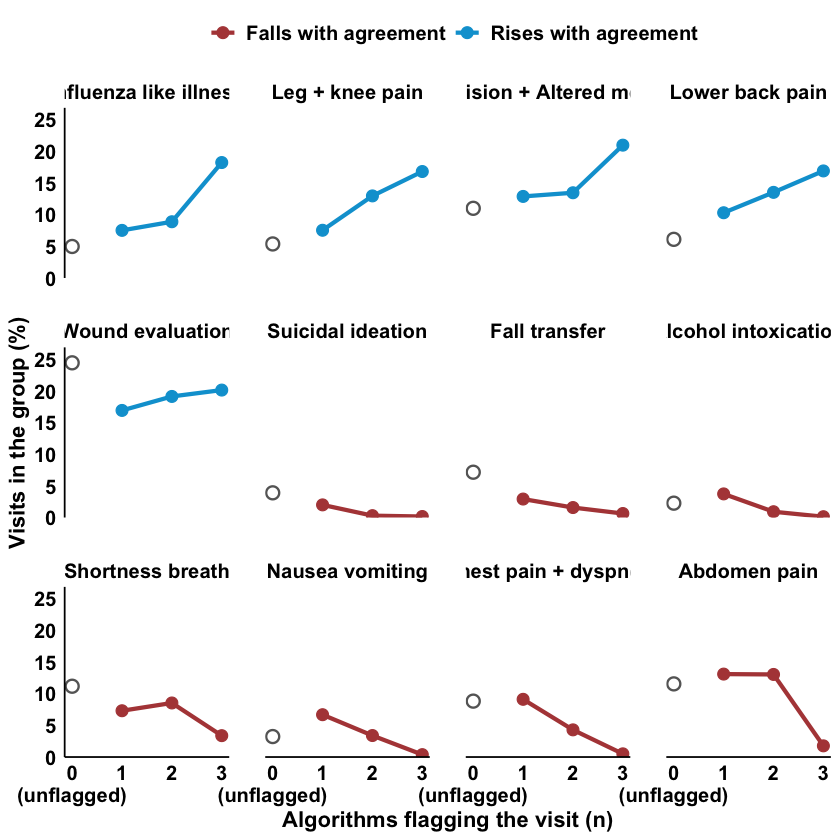

In [21]:
jama_palette <- ggsci::pal_jama()(7)

figure_data <- ed_data |>
  count(n_algorithms, cluster_label) |>
  group_by(n_algorithms) |>
  mutate(pct = 100 * n / sum(n)) |>
  ungroup() |>
  left_join(
    dose_wide |> select(cluster_label, direction),
    by = "cluster_label"
  ) |>
  mutate(
    cluster_label = factor(cluster_label, levels = dose_wide$cluster_label)
  )

figure_1 <- ggplot(
    figure_data |> filter(n_algorithms >= 1),
    aes(x = n_algorithms, y = pct, colour = direction)
  ) +
  geom_point(
    data = figure_data |> filter(n_algorithms == 0),
    shape = 21,
    size = 3,
    stroke = 1,
    colour = "grey40",
    fill = "white"
  ) +
  geom_line(linewidth = 1.2) +
  geom_point(size = 3) +
  facet_wrap(~cluster_label, ncol = 4) +
  scale_x_continuous(
    breaks = 0:3,
    labels = c("0\n(unflagged)", "1", "2", "3")
  ) +
  scale_y_continuous(
    limits = c(0, NA),
    expand = expansion(mult = c(0, 0.1))
  ) +
  scale_colour_manual(values = c(
    "Rises with agreement" = jama_palette[3],
    "Falls with agreement" = jama_palette[4]
  )) +
  labs(
    x = "Algorithms flagging the visit (n)",
    y = "Visits in the group (%)",
    colour = ""
  ) +
  theme_minimal() +
  theme(
    panel.grid = element_blank(),
    axis.line = element_line(color = "black"),
    panel.spacing = unit(1.5, "lines"),
    legend.position = "top",
    strip.text = element_text(size = rel(1.1), colour = "black", face = "bold"),
    axis.text = element_text(size = rel(1.1), colour = "black", face = "bold"),
    axis.title = element_text(size = rel(1.2), colour = "black", face = "bold"),
    legend.text = element_text(size = rel(1.1), colour = "black", face = "bold")
  )

ggsave("s3_figure_1.png", plot = figure_1, device = "png", width = 15, height = 10, units = "in", dpi = 600)
ggsave("s3_figure_1.svg", plot = figure_1, device = "svg", width = 15, height = 10, units = "in")
ggsave("s3_figure_1.pdf", plot = figure_1, device = "pdf", width = 15, height = 10, units = "in")

figure_1

# What this says

Agreement between the algorithms does track something real. Length of stay holds up under every restriction I tried, and the complaint mix moves steadily from one algorithm to three - influenza like illness and limb pain climbing, chest pain and vomiting all but disappearing by three. Neither of those is an input to any algorithm. So a visit flagged by more than one algorithm is a more conservative definition of avoidability, and using agreement as a stricter threshold is defensible.

What is not evidence for it is the acuity and admission gap. `acuity_out` is a recode of the triage score and `res` forbids admission outright, so those two differences are forced by the definitions, and there is no stratum where they can be compared free of both. They are in the table marked as definitional and they should be read that way.